# 國立陽明交通大學 - 多模態影像資料處理 (MMIP) 2026 Fall
## Assignment 07：多模態語言模型（LLM 部署／評估／提示工程／量化、VLM 比較、DPO 微調）

- **學生**：林孟霆（`315833033`）
- **作業規範**：課程簡報第 64–66 頁（作業一：大型語言模型、作業 B：視覺多模態大模型、作業 C：以 DPO 微調 LLM / VLM）
- **完整文字報告與結果分析**：請見同目錄 `README.md`

| 部分 | 模型 | 內容 |
| :--- | :--- | :--- |
| 作業一 | Qwen3-4B-Instruct-2507 | 部署、20 題自訂 Instruction Benchmark、8 種 Prompt 技巧、FP16 / INT8 / NF4、GPU 記憶體量測 |
| 作業 B | Qwen3-VL-2B-Instruct vs SmolVLM2-2.2B-Instruct | 20 題自訂視覺 Benchmark，規則式指標 + Gemini 評審 |
| 作業 C | Qwen3-4B-Instruct-2507 + LoRA | DPO：台灣繁體中文用語（130 組偏好資料）＋ 100 題通用能力（MMLU / GSM8K） |
| 作業 C 進階 | Qwen3-VL-2B-Instruct + LoRA | DPO：減少物件幻覺（COCO，最多 450 組）＋ POPE / CHAIR ＋ 7 種影像劣化 |

### 在 Google Colab 執行（T4 GPU，約 1.5 小時）
1. 建議把 `HW07/` 放到 Google Drive 的 `MyDrive/MMIP/HW07`（斷線後重新執行會從快取接續，不會重跑已完成的部分）；或壓縮成 `HW07.zip` 拖到 Colab 左側「檔案」區（斷線後快取會消失）。
2. 「執行階段 → 變更執行階段類型」選 **T4 GPU**。
3. （選用）左側「Secrets」（鑰匙圖示）加入 `GEMINI_API_KEY` 並開啟 Notebook 存取權；沒有 Key 時只跳過 Gemini 評審，其餘照常執行。
4. 「執行階段 → 全部執行」。跑完後執行最後一格下載 `HW07_results.zip`，並用「檔案 → 下載 → 下載 .ipynb」下載已執行的 Notebook。

### 在實驗室伺服器（RTX 2080 Ti 11 GB）執行
`pip install -r requirements.txt` 後執行 `python HW07_main.py`（或用 Jupyter 開這份 Notebook）。共用伺服器請先用 `nvidia-smi` 確認 GPU 空閒，必要時設定 `CUDA_VISIBLE_DEVICES=<id>`。

---
### 給助教：閱讀這份 Notebook 前請先看
這份 Notebook 是在 Google Colab **Tesla T4** 上實際執行的紀錄，所有程式輸出都保留原樣。完整的結果表格與分析請以 **`README.md`** 為準（README 最上方的「評分項目對照表」列出每一小題要看的段落與檔案）。

執行過程中有幾處需要說明。以 **「說明」** 開頭的引用框是事後加入的文字，沒有改動任何程式或輸出：
1. 最上方的 `pip install transformers==5.15.0` 格與作業 C 前的 torchao 格，是執行時為了排除 Colab 環境問題而加入的，原因寫在各格前面。
2. **GPU 速度量測格**只完成前半段（矩陣乘法與頻寬），後半段因 Colab 預裝的舊版 torchao 報錯；T4 的實測速度請看 README「執行環境與速度評估」。
3. **作業一**表格中的「規則式通過」是**修正前**的數字：A17（表格推理）的檢查規則有誤，把 6 個答對的回答判錯。修正後的數字在作業一輸出下方的說明格，以及 `Output/partA_*.csv`。
4. **作業 C** 的輸出包含「DPO」與「DPO+SFT」兩個版本：DPO 是失敗案例（模型退化），DPO+SFT 是修正後的版本，說明見作業 C 輸出下方。
5. 每個部分都有快取，中途重新啟動只會重算尚未完成的部分：作業一的生成在第一次執行時完成（Notebook 顯示的是讀取這些結果後的輸出）；作業 B、作業 C 進階在第一次執行完成；作業 C 的 DPO+SFT 在第二次執行時訓練。
---

> **說明（執行時加入的格）**：Colab 預設版本的 transformers 中，SmolVLM2 的 `inputs_merger` 會以視覺編碼器的 patch size（14）重塑影像特徵，與 SmolVLM2 每個子圖 81 個 token 不符，作業 B 因此報錯（`shape '[-1, 14, 2048]' is invalid`）。改裝本機測試過的 **transformers 5.15.0** 並重新啟動後才執行作業 B 以後的部分；`requirements.txt` 已固定此版本。作業一是在 Colab 預設版本上執行的。

In [5]:
!pip -q install transformers==5.15.0

In [1]:
%matplotlib inline
import os, sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    if os.path.exists('/content/HW07.zip'):
        !unzip -q -o /content/HW07.zip -d /content/
    if os.path.exists('/content/HW07/Code'):
        os.chdir('/content/HW07')
    else:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/MMIP/HW07')
    !pip -q install -r requirements.txt
sys.path.insert(0, os.getcwd())

import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from Code.common import gpu_info
from Code.gemini import get_api_key
pd.set_option('display.max_colwidth', 120)
print(f"Working dir: {os.getcwd()}")
print(f"PyTorch {torch.__version__} | {gpu_info()}")
print('GEMINI_API_KEY:', 'found' if get_api_key() else 'not found -> Gemini judge skipped')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working dir: /content/drive/MyDrive/MMIP/HW07
PyTorch 2.11.0+cu130 | {'device': 'cuda', 'name': 'Tesla T4', 'vram_gb': 14.56, 'capability': '7.5', 'torch': '2.11.0+cu130'}
GEMINI_API_KEY: found


### （選用）GPU 速度量測
量測 FP16 矩陣乘法、記憶體頻寬、Qwen3-4B FP16 解碼速度與一步 DPO 訓練時間，結果存於 `Output/gpu_benchmark_<GPU>.json`（約 3 分鐘）。在 Colab T4 與實驗室 2080 Ti 各執行一次即可比較兩邊速度。

In [7]:
!python gpu_benchmark.py

{'device': 'cuda', 'name': 'Tesla T4', 'vram_gb': 14.56, 'capability': '7.5', 'torch': '2.11.0+cu130', 'bf16_native': False, 'fp16_matmul_tflops': 21.7, 'fp32_matmul_tflops': 3.7, 'mem_bandwidth_gbs': 234.0}
Loading weights: 100% 398/398 [00:31<00:00, 12.83it/s]
Traceback (most recent call last):
  File "/content/drive/MyDrive/MMIP/HW07/gpu_benchmark.py", line 83, in <module>
    main()
    ~~~~^^
  File "/content/drive/MyDrive/MMIP/HW07/gpu_benchmark.py", line 62, in main
    pm = dpo.add_lora(model, r=16)
  File "/content/drive/MyDrive/MMIP/HW07/Code/dpo.py", line 37, in add_lora
    pm = get_peft_model(model, cfg)
  File "/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py", line 190, in get_peft_model
    return PeftModel(
        model,
    ...<3 lines>...
        low_cpu_mem_usage=low_cpu_mem_usage,
    )
  File "/usr/local/lib/python3.13/dist-packages/peft/peft_model.py", line 177, in __init__
    self.base_model = cls(model, {adapter_name: peft_config}, adapter_name)
 

> **說明**：上一格前半段已實測到 T4 的 FP16 矩陣乘法 21.7 TFLOPS、FP32 3.7 TFLOPS、記憶體頻寬 234 GB/s（輸出最上方的 dict）；後半段在建立 LoRA 時，新版 peft 因 Colab 預裝的舊版 torchao（0.10）報錯而中斷，所以沒有量到 LLM 解碼與 DPO 步驟，也沒有存成 json。本作業不使用 torchao，`Code/dpo.py` 已加入修正（讓 peft 忽略不相容的 torchao），重新執行即可完成。T4 的實測速度（例如 Qwen3-4B FP16 單筆 15.1 tok/s、DPO 訓練時間）已整理在 README「執行環境與速度評估」。

---
## 作業一：大型語言模型（基礎 20 分 + 進階 10 分）

**簡報要求（第 64 頁）**
- 基礎：（5）成功部署並執行一個開源 LLM；（5）設計 20 道涵蓋不同能力面向的自定義 Instruction Benchmark；（5）應用課程介紹的 Prompting Techniques 並透過量化指標或商用 LLM 評估成效；（5）調整開源 LLM 的數值精度，使用預設 Prompt 並透過量化指標與商用 LLM 評估效能。
- 進階：（5）測量預設精度下 LLM 推論過程的平均 GPU 記憶體使用量；（5）結合優化後的 Prompt 與低精度量化模型進行推論，測量 GPU 記憶體使用量並比較成效。

**做法**
- **模型**：`Qwen/Qwen3-4B-Instruct-2507`（4.0 B，FP16 權重 8 GB；簡報第 17 頁推薦的 Qwen3-4B / FP16）。
- **Benchmark**：`Data/partA_llm_benchmark.json`，20 題各測一種能力（數學、邏輯、日期、字串、程式撰寫／理解、知識、抗幻覺、翻譯、摘要、JSON／條列／句數格式、情緒分類、表格推理、安全拒答、限制式寫作、單位換算），每題都有**規則式自動檢查**（量化指標）與給 Gemini 的參考答案。
- **Prompt 技巧**（簡報第 30–35 頁）：Zero-shot（預設）、Zero-shot CoT、Few-shot、Emotional Stimuli、XML、Markdown、組合（中文系統提示）、組合（英文系統提示）。
- **精度**：FP16（預設）、INT8（bitsandbytes LLM.int8）、NF4（4-bit + double quant）。
- **GPU 記憶體**：背景執行緒每 20 ms 取樣 `torch.cuda.memory_allocated()`（權重 + KV cache + 中間值）、`memory_reserved()` 與 NVML（nvidia-smi 看到的本程序用量），計算平均與峰值；另做 batch = 1 的單一請求記憶體曲線。
- **評估**：規則式通過率 + Gemini 對每題所有設定的回答（匿名、打亂順序）打 1–10 分。

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[Part A] Qwen/Qwen3-4B-Instruct-2507 fp16: footprint 7672.2 MiB, load 32.8 s
[Part A] best prompting technique on FP16: zero_shot_cot


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[Part A] Qwen/Qwen3-4B-Instruct-2507 int8: footprint 4207.2 MiB, load 37.1 s


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

精度 × Prompt（最佳 Prompt = zero_shot_cot）：


,precision,technique,footprint_mib,auto_pass,auto_pass_rate,gemini_mean,avg_new_tokens,tokens_per_s,seconds,avg_allocated_mib,peak_allocated_mib,avg_process_mib
0,fp16,baseline,7672.2,19,0.95,9.65,145.6,44.57,65.33,8162.5,8682.0,8642.2
1,fp16,zero_shot_cot,7672.2,20,1.00,9.30,232.6,45.99,101.17,8366.6,9066.4,8966.0
2,int8,baseline,4207.2,19,0.95,9.65,150.2,12.99,231.30,4742.8,5401.1,5371.3
3,int8,zero_shot_cot,4207.2,20,1.00,9.60,213.7,21.69,197.06,4707.2,5189.5,5864.0
4,nf4,baseline,2474.7,19,0.95,9.35,165.6,32.69,101.29,3150.0,3848.9,3726.5
5,nf4,zero_shot_cot,2474.7,20,1.00,9.45,258.9,48.02,107.82,3216.1,3925.5,4282.0


Batch-1 GPU 記憶體量測：


,precision,technique,footprint_mib,tokens_per_s_batch1,b1_avg_allocated_mib,b1_peak_allocated_mib,b1_avg_reserved_mib,b1_peak_reserved_mib,b1_avg_process_mib,b1_seconds
0,fp16,baseline,7672.2,15.07,7701.3,7741.6,9303.9,9316.0,9435.9,26.47
1,fp16,zero_shot_cot,7672.2,15.06,7710.9,7750.8,9318.0,9322.0,9450.0,55.59
2,int8,baseline,4207.2,4.61,4241.5,4313.2,5710.4,5724.0,5850.4,89.85
3,int8,zero_shot_cot,4207.2,4.67,4250.5,4326.7,5724.7,5730.0,5864.7,171.67
4,nf4,baseline,2474.7,11.35,2561.8,2604.6,4122.4,4132.0,4262.4,45.99
5,nf4,zero_shot_cot,2474.7,11.38,2568.7,2615.4,4178.0,4180.0,4318.0,76.56


precision     fp16                                                        \
technique baseline combined_en combined_zh emotion few_shot markdown xml   
id                                                                         
A01              1           1           1       1        1        1   1   
A02              1           1           1       1        1        1   1   
A03              1           1           1       1        0        0   0   
A04              1           0           0       1        0        0   0   
A05              1           0           0       0        0        0   0   
A06              1           0           1       1        1        1   1   
A07              1           1           1       1        1        0   0   
A08              1           1           1       1        1        1   1   
A09              1           1           1       1        1        1   1   
A10              1           1           1       1        1        1   1   
A11              1           1           1       1        1        1   1   
A12              1           1           1       1        1        1   1   
A13              1           1           1       1        1        1   1   
A14              1           1           1       1        1        1   1   
A15              1           1           1       1        1        1   1   
A16              1           1           1       1        1        1   1   
A17              0           1           1       0        1        0   0   
A18              1           1           1       1        1        1   1   
A19              1           1           1       1        0        1   1   
A20              1           1           1       1        1        1   1   

precision                   int8                    nf4                
technique zero_shot_cot baseline zero_shot_cot baseline zero_shot_cot  
id                                                                     
A01                   1        1             1        1             1  
A02                   1        1             1        1             1  
A03                   1        1             1        1             1  
A04                   1        1             1        1             1  
A05                   1        1             1        1             1  
A06                   1        1             1        1             1  
A07                   1        1             1        1             1  
A08                   1        1             1        1             1  
A09                   1        1             1        1             1  
A10                   1        1             1        1             1  
A11                   1        1             1        1             1  
A12                   1        1             1        1             1  
A13                   1        1             1        1             1  
A14                   1        1             1        1             1  
A15                   1        1             1        1             1  
A16                   1        1             1        1             1  
A17                   1        0             1        0             1  
A18                   1        1             1        1             1  
A19                   1        1             1        1             1  
A20                   1        1             1        1             1

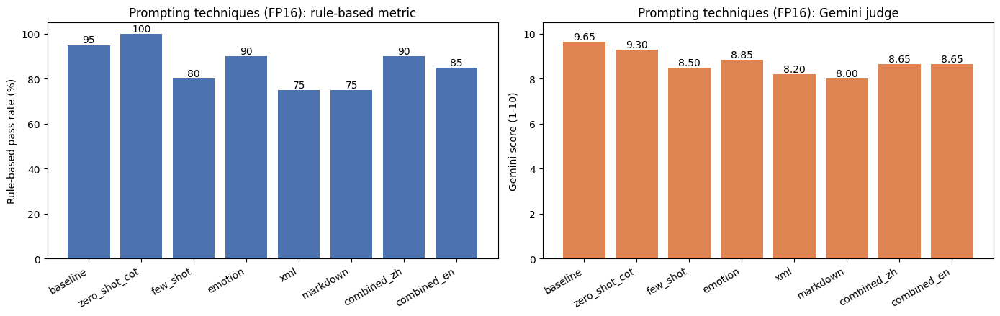

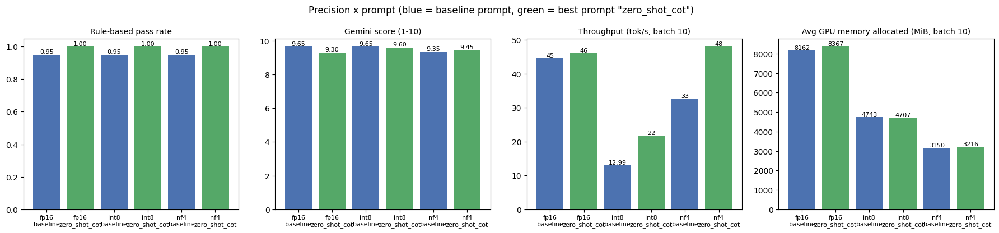

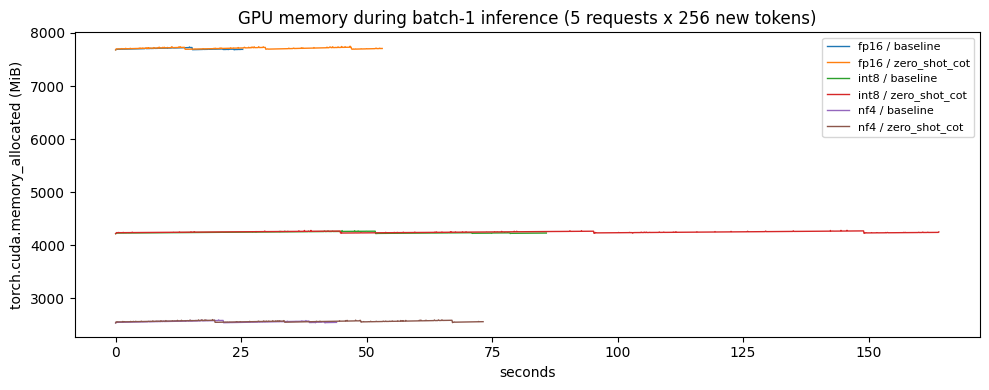

In [8]:
from Code.partA_llm import run_partA
A = run_partA()
plt.close('all')
print('部署示範：'); display(A['demo'])
print('Prompt 技巧（FP16）：'); display(A['techniques'])
print(f"精度 × Prompt（最佳 Prompt = {A['best']}）："); display(A['quant'])
print('Batch-1 GPU 記憶體量測：'); display(A['profile'])
display(A['by_question'])
for f in A['figures'].values():
    display(f)

> **說明：作業一規則式檢查的修正（上方輸出為修正前的數字）**
>
> 執行後逐題檢查回答，發現 **A17（表格推理）** 的檢查規則有誤：原規則要求答案中「只能出現小強」，但沒有「最終答案：」標記的回答會在計算過程中列出三位同學的分數，因此 6 個**答對**的回答（Gemini 都給 10 分）被判為錯誤。規則改為「最後提到的人名是否為小強」，並以**已存檔的回答**重新計分：模型回答完全沒有重新生成，240 個判定中只有這 6 個改變，Gemini 分數不受影響。最佳 Prompt 仍是 `zero_shot_cot`。
>
> **Prompt 技巧（FP16）**
>
> | Prompt | 修正前 | 修正後 | Gemini 平均 |
> | :--- | ---: | ---: | ---: |
> | `baseline` | 19 / 20 | **20 / 20** | 9.65 |
> | `zero_shot_cot` | 20 / 20 | **20 / 20** | 9.30 |
> | `few_shot` | 16 / 20 | **16 / 20** | 8.50 |
> | `emotion` | 18 / 20 | **19 / 20** | 8.85 |
> | `xml` | 15 / 20 | **16 / 20** | 8.20 |
> | `markdown` | 15 / 20 | **16 / 20** | 8.00 |
> | `combined_zh` | 18 / 20 | **18 / 20** | 8.65 |
> | `combined_en` | 17 / 20 | **17 / 20** | 8.65 |
>
> **精度 × Prompt**
>
> | 精度 | Prompt | 修正前 | 修正後 | Gemini 平均 | 平均 GPU 記憶體（MiB, batch 10） |
> | :--- | :--- | ---: | ---: | ---: | ---: |
> | fp16 | `baseline` | 19 / 20 | **20 / 20** | 9.65 | 8,162 |
> | fp16 | `zero_shot_cot` | 20 / 20 | **20 / 20** | 9.30 | 8,367 |
> | int8 | `baseline` | 19 / 20 | **20 / 20** | 9.65 | 4,743 |
> | int8 | `zero_shot_cot` | 20 / 20 | **20 / 20** | 9.60 | 4,707 |
> | nf4 | `baseline` | 19 / 20 | **20 / 20** | 9.35 | 3,150 |
> | nf4 | `zero_shot_cot` | 20 / 20 | **20 / 20** | 9.45 | 3,216 |
>
> 另外，部署示範（`partA_deploy_demo.csv`）的峰值記憶體 12,083 MiB 偏高：該示範是在作業 B 出錯後、重新啟動前不小心重跑作業一時產生的，當時出錯的 SmolVLM2 模型仍佔用 GPU。記憶體請以上方「Batch-1 GPU 記憶體量測」表（FP16 平均 7,701 MiB）為準。

---
## 作業 B：視覺多模態大模型（基礎 20 分）

**簡報要求（第 65 頁）**：（10）成功部署並執行兩個開源 VLM；（5）自行設計 20 道與視覺理解相關的 Benchmark；（5）使用同樣的 Prompt 測試兩個 VLM，透過量化指標與商用 LLM 評估效能。

**做法**
- **模型**（簡報第 57 頁）：`Qwen/Qwen3-VL-2B-Instruct` 與 `HuggingFaceTB/SmolVLM2-2.2B-Instruct`，FP16。
- **Benchmark**：`Data/partB_vlm_benchmark.json`，15 張 COCO 真實照片（逐張看過後撰寫答案）+ 5 張程式產生的合成影像（答案精確）：影像分類、物件／人物計數、場景文字 OCR、顏色、空間關係、多物件偵測、運動辨識、情境推理、細粒度辨識、幻覺探測、形容照片、招牌 OCR、圖表理解、視覺數學。
- **評估**：同一個英文 Prompt（兩個模型都能理解）、greedy decoding；規則式準確率（數字比對、關鍵字、Yes/No）+ Gemini 看圖評分（1–10）+ 延遲與 GPU 記憶體。

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

[Part B] SmolVLM2-2.2B: auto 17/20, footprint 4285.4 MiB
[Part B] Gemini judge: gemini-3.5-flash-lite
  [gemini] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand  -> retry in 5s


,model,hf_id,auto_acc,auto_pass,auto_acc_coco,auto_acc_synthetic,gemini_mean,avg_latency_s,avg_new_tokens,prompt_tokens_640x480,footprint_mib,avg_allocated_mib,peak_allocated_mib
0,Qwen3-VL-2B,Qwen/Qwen3-VL-2B-Instruct,0.90,18,1.000,0.6,8.75,2.018,36.4,271,4057.9,4112.4,4116.6
1,SmolVLM2-2.2B,HuggingFaceTB/SmolVLM2-2.2B-Instruct,0.85,17,0.933,0.6,8.65,1.187,7.4,1092,4285.4,4393.8,4508.9


,id,task,model,answer,auto,gemini_score
0,B01,影像分類,Qwen3-VL-2B,elephant,1,10
1,B02,物件計數,Qwen3-VL-2B,3,1,10
2,B03,物件計數,Qwen3-VL-2B,2,1,10
3,B04,小物件計數,Qwen3-VL-2B,2,1,10
4,B05,人物計數,Qwen3-VL-2B,3,1,10
5,B06,場景文字辨識 (OCR),Qwen3-VL-2B,"Based on the image provided, the word written on the sign is **STOP**.\n\nThe sign is a standard red octagonal stop ...",1,10
6,B07,場景文字辨識 (OCR),Qwen3-VL-2B,4,1,10
7,B08,屬性辨識（顏色）,Qwen3-VL-2B,brown,1,10
8,B09,空間關係,Qwen3-VL-2B,"Based on the image provided, the cat is sitting in a **white bathroom sink**.\n\nHere are the key details:\n- The si...",1,10
9,B10,多物件偵測,Qwen3-VL-2B,"Based on the image provided, two kinds of animals can be seen:\n\n- A **cat**. It is a gray cat sitting on a wooden ...",1,7


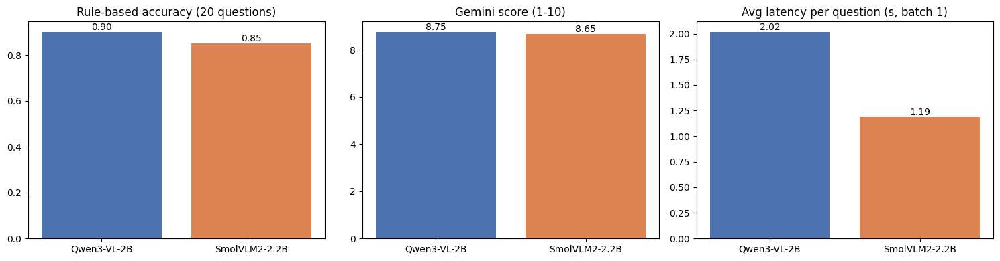

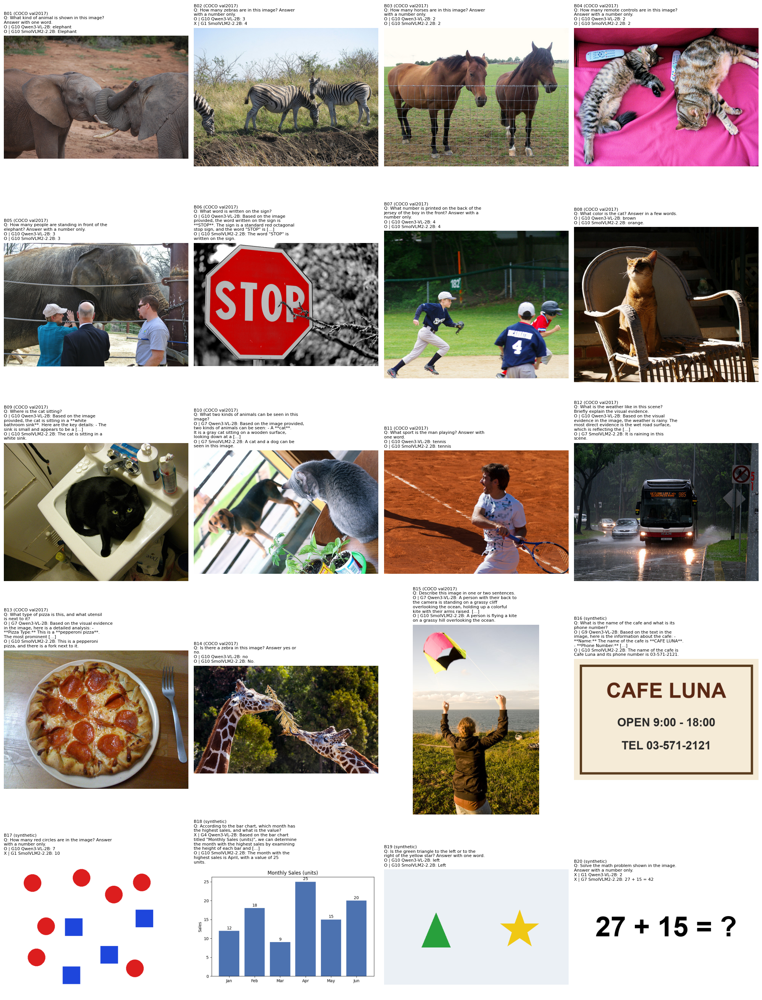

In [2]:
from Code.partB_vlm import run_partB
B = run_partB()
plt.close('all')
display(B['summary'])
display(B['answers'][['id', 'task', 'model', 'answer', 'auto', 'gemini_score']])
for f in B['figures'].values():
    display(f)

> **說明（執行時加入的格）**：作業 C 建立 LoRA 時，新版 peft 會因 Colab 預裝的舊版 torchao（0.10，peft 要求 ≥ 0.16）而報錯。本作業用不到 torchao，這一格讓 peft 把不相容的 torchao 視為未安裝。之後此修正已寫進 `Code/dpo.py`，重新執行時不需要這一格。

In [2]:
# 讓 peft 忽略 Colab 預裝的舊版 torchao（本作業用不到 torchao）
import importlib
for name in ('peft.import_utils', 'peft.tuners.lora.torchao', 'peft.utils.quantization_utils'):
    mod = importlib.import_module(name)
    if hasattr(mod, 'is_torchao_available'):
        mod.is_torchao_available = lambda: False
print('ok')

ok


---
## 作業 C：以 DPO 微調 LLM（基礎 20 分）

**簡報要求（第 66 頁）**：（5）自行決定優化面向、準備 RLHF 所需之訓練資料集，至少 100 組；（5）準備另外 100 組與優化面向無關之 Benchmark，用於測試通用能力；（10）實際微調開源 LLM，量化優化面向是否提升、量化另外的 Benchmark 是否表現有改變。

**做法**
- **優化面向**：使用者以繁體中文提問時，以**台灣繁體中文**回答——不夾雜簡體字、不使用中國大陸用語（軟件→軟體、視頻→影片、默認→預設⋯）。指標完全自動計算（OpenCC 簡體字表 + 人工整理的兩岸用語對照表）。
- **偏好資料**：130 題自行撰寫的繁中問題 → 基礎模型作答 → chosen = 修正簡體字與大陸用語後的回答；rejected = 模型原本的回答（on-policy）；若原回答已正確，則把台灣用語換回大陸用語（或轉簡體）作為 rejected。共 130 組（117 訓練 / 13 驗證）。
- **通用能力**：100 題英文題目（60 題 MMLU、40 題 GSM8K），與優化面向無關。
- **訓練**：DPO（β = 0.1）+ LoRA（r = 16，所有 attention / MLP 投影層），參考模型 = 關閉 LoRA 的同一個模型；FP16 autocast。
- **實際執行的兩個版本**：DPO（標準 DPO loss）與 DPO+SFT（DPO loss + 1.0 × chosen 的每 token NLL，RPO；資料與超參數相同）。DPO+SFT 是在檢查第一次結果、發現 DPO 退化後加入的，見下方說明。


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[Part C/LLM] 130 preference pairs: {'injected_terms': 76, 'on_policy': 31, 'simplified': 23}
[Part C/LLM] DPO: loaded trained adapter from /content/drive/MyDrive/MMIP/HW07/Checkpoints/partC_llm_dpo_lora
[Part C/LLM] training DPO+SFT: {'beta': 0.1, 'lr': 0.0001, 'epochs': 3, 'grad_accum': 8, 'sft_alpha': 1.0}
[dpo] LoRA r=16: 33.03 M trainable / 4.06 B total parameters
[dpo] epoch 0  val loss 0.6931 acc 0.000  (reference log-probs 29 s)
  step   10/45  loss 0.7401  acc 0.88  margin 18.89  chosen -10.99  rejected -29.88  142s
[dpo] epoch 1  train loss 0.7460  val loss 0.3035 acc 0.846 margin 39.29  chosen -4.03  rejected -43.32
  step   20/45  loss 0.4243  acc 1.00  margin 64.45  chosen +0.62  rejected -63.83  251s
  step   30/45  loss 0.2681  acc 1.00  margin 79.01  chosen +5.43  rejected -73.58  357s
[dpo] epoch 2  train loss 0.4321  val loss 0.2834 acc 0.923 margin 43.50  chosen +0.36  rejected -43.14
  step   40/45  loss 0.3619  acc 1.00  margin 57.43  chosen +9.28  rejected -48.15  

,model,n,clean_rate,chinese_answer_rate,with_simplified_rate,with_mainland_term_rate,terms_per_response,terms_per_1k_chars,simplified_per_1k_chars,with_other_script_rate,avg_cjk_chars
0,Base,40,0.700,1.0,0.075,0.225,0.375,2.662,0.710,0.000,140.9
1,DPO,40,0.225,1.0,0.775,0.000,0.000,0.000,12.219,0.075,167.8
2,DPO+SFT,40,0.750,1.0,0.175,0.075,0.075,0.524,2.270,0.000,143.2


通用能力（100 題）：


,model,MMLU_acc (60),GSM8K_acc (40),overall_acc (100)
0,Base,0.7667,0.875,0.81
1,DPO,0.8000,0.925,0.85
2,DPO+SFT,0.7667,0.925,0.83


{'DPO': {'base_correct_now_wrong': 0, 'base_wrong_now_correct': 4}, 'DPO+SFT': {'base_correct_now_wrong': 0, 'base_wrong_now_correct': 2}}


,Base,DPO,DPO+SFT
打印,4,0,0
土豆,2,0,0
激光,2,0,1
人工智能,1,0,0
信號,1,0,0
卸載,1,0,1
存儲,1,0,0
智能,1,0,0
渠道,1,0,0
空調,1,0,1


,prompt,Base_terms,DPO_terms,DPO+SFT_terms,Base_simplified,DPO_simplified,DPO+SFT_simplified,Base_response,DPO_response,DPO+SFT_response
0,手機和電腦的資料要怎麼同步？（請用 200 字以內回答）,,,,0,8,0,手機和電腦資料同步可透過雲端服務實現，如 Google Drive、iCloud 或 OneDrive。將手機與電腦登入相同帳號，並安裝相應應用程式（如 Google 記事、iCloud 套件），設定自動同步。也可使用備份工具（如 ...,手機與電腦資料同步可透過雲端储存（如 Google Drive、iCloud、OneDrive）或行动助理（如 iPhone 的 iCloud、Windows 的 Action Center）完成。設定方式：開啟装置設定，登入相同帳...,手機和電腦資料同步可透過雲端服務實現，如 Google Drive、iCloud 或 OneDrive。將手機與電腦登入相同帳戶，設定同步功能（如聯絡人、備註、檔案等），即可自動同步。此外，使用同步工具如 Microsoft One...
1,請介紹如何在電腦上安裝與移除軟體。（請用 200 字以內回答）,卸載,,卸載,0,2,0,在電腦上安裝軟體，通常透過下載官方提供的安裝檔（如 .exe 或 .dmg），執行後依照提示完成設定。移除軟體則可透過「控制面板」或「設定」中的「應用程式」，選取欲移除的項目並點選「卸載」。Windows 系統也可使用「程式與功能」...,在電腦上安裝軟體可透過官方网站下載建立体檔（如.exe、.dmg、.app），開啟後依指示完成設定；或從設定-Menü（Windows）或應用程式（Mac）中搜尋安裝。移除軟體則可前往設定＞應用程式（Windows）或應用程式 fo...,在電腦上安裝軟體，通常透過下載官方提供的安裝程式（如 .exe 或 .dmg 檔案），執行後依照提示完成安裝。移除軟體則可透過「設定」或「控制面板」中的「應用程式」選項，選取欲移除的軟體並點選「卸載」。Windows 系統也可使用「...
2,電腦的記憶體和硬碟容量有什麼不同？（請用 200 字以內回答）,,,,0,1,0,電腦的記憶體（RAM）和硬碟容量功能不同。記憶體用於暫時儲存正在運行的程式和資料，速度很快，但斷電後資料會消失；硬碟則用於長期儲存系統檔案、資料和應用程式，容量大但讀取速度較慢。記憶體越大，多任務處理能力越強；硬碟容量越大，能儲存越...,電腦的記憶體（RAM）與硬碟容量功能不同，用途也異樣。記憶體用於暫存作業中所需的ansom，讓電腦快速執行程式與多任务處理，單位為位元組（GB），愈大愈順暢，但斷電後資料會消失。硬碟（或 SSD）用於儲存系統檔案、程式、檔案等長期資...,電腦的記憶體（RAM）和硬碟容量功能不同。記憶體用於暫時儲存正在運行的程式和資料，速度快，但斷電後資料會消失；硬碟（或SSD）用於長期儲存系統、檔案和應用程式，容量大，但讀取速度較慢。記憶體影響電腦運行順暢度，硬碟決定可儲存的資料量...
3,如何設定一個安全的家用無線網路？（請用 200 字以內回答）,,,,1,4,0,設定安全家用無線網路 steps： \n1. 更改預設的網路名稱（SSID）和密碼，避免使用個人資訊。 \n2. 使用強密碼，包含大小寫、數字和符號，長度至少8位。 \n3. 启用WPA3加密（若支援），否則使用WPA2。 ...,設定安全的家用無線網路請务必：使用強韧的密碼（建議搭配大小寫、數字、符號），關閉遠端登入，更新路由器irmware，啟用網路加密（建議選用 WPA3，舊機體則用 WPA2-psk），設定獨一無二的網路名稱（SSID），避免顯示個人資...,設定安全的家用無線網路應從以下幾點著手：首先，設定強密碼（避免使用生日或簡單字詞），並啟用WPA3加密（或WPA2若無WPA3）；其次，更換預設的網路名稱（SSID）與管理密碼；第三，關閉遠端管理與自動更新功能，並定期更新路由器固體...
4,請解釋什麼是雲端儲存，以及使用上要注意什麼。（請用 200 字以內回答）,存儲,,,0,3,0,雲端儲存是將資料存放在遠端伺服器上，透過網路隨時從任何裝置存取的服務，如Google Drive、iCloud或Dropbox。使用時應注意：保護帳號密碼，啟用雙重驗證；避免存儲敏感資料如銀行資訊；定期備份並確認資料完整性；留意服務...,雲端儲存是指將資料儲存於遠端伺服器網路中，透過網路隨時從任何裝體.access，如行動裝體、智慧型手機或電腦，達到便利儲存與分享的目的，常用例項有 Google Drive、iCloud、簡體雲端等。使用上要注意資料安全性、Priv...,雲端儲存是將資料儲存在遠端伺服器上，透過網路隨時從任何裝置存取的服務，如Google Drive、OneDrive或iCloud。優點是便於分享、備份與同步，節省硬體空間。使用上要注意：確保使用可靠且加密的服務，避免儲存敏感資料；設...


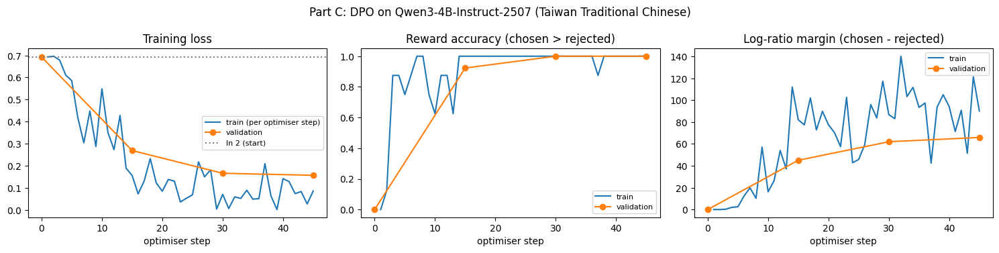

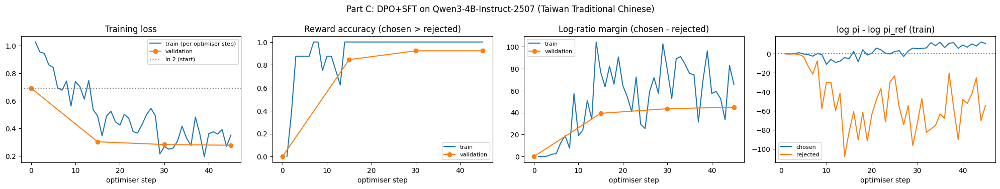

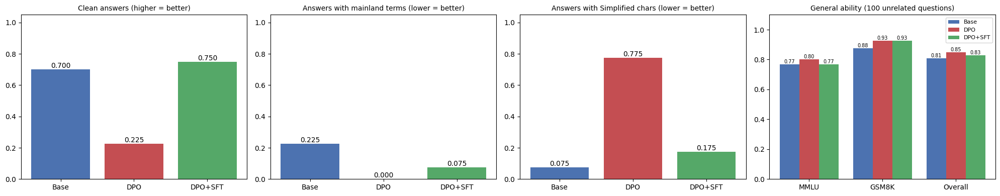

In [2]:
from Code.partC_dpo_llm import run_partC_llm
C = run_partC_llm()
plt.close('all')
print('偏好資料組成：', C['pair_kinds'])
print('優化面向（40 題保留測試題）：'); display(C['aspect'])
print('通用能力（100 題）：'); display(C['general']); print(C['flips'])
display(C['terms'].head(20))
display(C['examples'].head(5))
for f in C['figures'].values():
    display(f)

> **說明：作業 C 的兩個版本**
>
> 上方輸出包含 Base、**DPO**、**DPO+SFT** 三列：
> - **DPO**（第一次執行）：大陸用語的回答從 22.5% 降到 0%，但含簡體字的回答從 7.5% 暴增到 77.5%，還出現日文、德文與亂碼。訓練資料的 chosen 中沒有任何簡體字，這是 DPO 的 **likelihood displacement**（chosen 與 rejected 只差幾個詞時，模型連 chosen 的機率也一起壓低：驗證資料上 chosen 的 log π − log π_ref = −135），驗證 DPO loss 偵測不到這種退化。
> - **DPO+SFT**（第二次執行）：資料與超參數完全相同，只在 loss 加上 chosen 的 NLL 項（RPO），chosen 的 log-ratio 維持在 +0.03。乾淨回答 70% → 75%，大陸用語的回答 9 題 → 3 題；含簡體字的回答仍從 3 題增加到 7 題（零星單字）。
> - 兩個版本的通用能力（MMLU + GSM8K）都沒有任何原本答對的題目變錯。
>
> 完整分析見 README「作業 C：以 DPO 微調 LLM」。

---
## 作業 C 進階：以 DPO 微調 VLM（進階 20 分）

**簡報要求（第 66 頁）**：（10）自行決定優化面向（如：描述照片時避免提及不存在的東西），準備所需資料集，至少 100 組；（5）實際微調開源 VLM，量化優化面向是否提升；（5）調整影像的畫質、明暗程度等，觀測影像平均表現。

**做法**
- **模型**：`Qwen/Qwen3-VL-2B-Instruct` + LoRA（只加在語言模型，視覺編碼器凍結），輸入影像上限 448×448 像素。
- **偏好資料**（COCO val2017 的 150 張影像，以 COCO 標註判斷物件是否存在）：描述類——模型自己的描述中提到不存在的物件 → rejected，刪除幻覺句子 → chosen；沒有幻覺時插入一句「常一起出現但不存在」的物件作為 rejected。是非題類——每張影像一個存在、一個不存在的物件。
- **評估**（另 80 張影像，不參與訓練）：POPE（480 題是非題，含 adversarial 負樣本）、CHAIR_s / CHAIR_i / 物件召回率。
- **影像劣化**：變暗、變亮、低對比、JPEG q=5、模糊、低解析度、雜訊，比較 Base 與 DPO 模型的 POPE 表現。

[ERROR] `min_frames` is part of Qwen3VLVideoProcessorInitKwargs, but not documented. Make sure to add it to the docstring of the function in /usr/local/lib/python3.13/dist-packages/transformers/models/qwen3_vl/video_processing_qwen3_vl.py.
[ERROR] `max_frames` is part of Qwen3VLVideoProcessorInitKwargs, but not documented. Make sure to add it to the docstring of the function in /usr/local/lib/python3.13/dist-packages/transformers/models/qwen3_vl/video_processing_qwen3_vl.py.


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  [Base] POPE original             acc 0.9146  F1 0.9172  yes 0.531
  [Base] POPE dark (x0.35)         acc 0.9229  F1 0.9240  yes 0.515
  [Base] POPE bright (x1.8)        acc 0.9021  F1 0.9039  yes 0.519
  [Base] POPE low contrast (x0.4)  acc 0.9187  F1 0.9193  yes 0.506
  [Base] POPE JPEG q=5             acc 0.9000  F1 0.8992  yes 0.492
  [Base] POPE blur r=4             acc 0.9062  F1 0.9064  yes 0.502
  [Base] POPE low-res 64 px        acc 0.8729  F1 0.8705  yes 0.481
  [Base] POPE noise sigma=50       acc 0.9229  F1 0.9234  yes 0.506
[Part C/VLM] 449 preference pairs: {'desc_on_policy': 43, 'desc_injected': 106, 'desc_skipped': 1, 'yes': 150, 'no': 150}
[dpo] LoRA r=16: 17.43 M trainable / 2.14 B total parameters
[dpo] epoch 0  val loss 0.6931 acc 0.000  (reference log-probs 128 s)
  step   10/102  loss 0.4475  acc 0.88  margin 6.81  236s
  step   20/102  loss 0.0740  acc 1.00  margin 27.10  330s
  step   30/102  loss 0.5021  acc 0.75  margin 17.56  423s
  step   40/102  loss 0.363

,model,condition,accuracy,precision,recall,f1,yes_ratio,auc,acc_adversarial_neg,acc_random_neg
0,Base,original,0.9146,0.8902,0.9458,0.9172,0.5312,0.9783,0.8313,0.9875
1,Base,dark (x0.35),0.9229,0.9109,0.9375,0.9240,0.5146,0.9752,0.8625,1.0000
2,Base,bright (x1.8),0.9021,0.8876,0.9208,0.9039,0.5188,0.9665,0.8250,1.0000
3,Base,low contrast (x0.4),0.9187,0.9136,0.9250,0.9193,0.5062,0.9738,0.8688,1.0000
4,Base,JPEG q=5,0.9000,0.9068,0.8917,0.8992,0.4917,0.9676,0.8688,0.9875
5,Base,blur r=4,0.9062,0.9046,0.9083,0.9064,0.5021,0.9733,0.8562,1.0000
6,Base,low-res 64 px,0.8729,0.8874,0.8542,0.8705,0.4813,0.9524,0.8375,1.0000
7,Base,noise sigma=50,0.9229,0.9177,0.9292,0.9234,0.5062,0.9747,0.8750,1.0000
8,DPO,original,0.9375,0.9449,0.9292,0.9370,0.4917,0.9729,0.9313,0.9750
9,DPO,dark (x0.35),0.9271,0.9325,0.9208,0.9266,0.4938,0.9713,0.9062,0.9875


,model,CHAIR_s,CHAIR_i,recall,objects_per_caption,avg_words
0,Base,0.2500,0.1182,0.6235,2.75,147.1
1,DPO,0.2375,0.0913,0.6700,3.01,94.2


,file_name,objects,base_hallucinated,dpo_hallucinated,base_description,dpo_description
0,000000038829.jpg,"backpack, bicycle, motorcycle, person",,,"This is a candid, street-level photograph capturing a busy urban scene in what appears to be a Southeast Asian city,...","The image captures a bustling street scene in a Southeast Asian city, likely Vietnam, given the visible signage and ..."
1,000000063740.jpg,"banana, cup, keyboard, laptop, orange, person, tv","cell phone, mouse","chair, dining table","This is a detailed description of the image provided.\n\nThe image captures a busy, modern office workspace, likely ...",The image depicts a typical office workspace with several objects and elements that suggest a professional environme...
2,000000241319.jpg,"bottle, cup, handbag, sink, toothbrush",,,"This is a low-angle, close-up photograph of a bathroom sink and countertop, capturing a mundane yet detailed scene o...",The image shows a bathroom sink area with several items placed on the countertop. The sink has a white marble-like s...
3,000000459153.jpg,"backpack, bench, laptop, person",,,"This is a detailed description of the image provided.\n\nThe image captures a candid, outdoor scene of a young man s...","The image shows a man sitting on a wooden bench in a park-like setting. He is wearing a gray t-shirt and dark pants,..."
4,000000527750.jpg,"bottle, bowl, oven, person, refrigerator",,,"This is a detailed description of the image provided.\n\nThe image captures a candid, indoor scene in a kitchen, ill...",The image depicts a kitchen scene with a person standing in the center. The person is wearing a gray tank top and da...


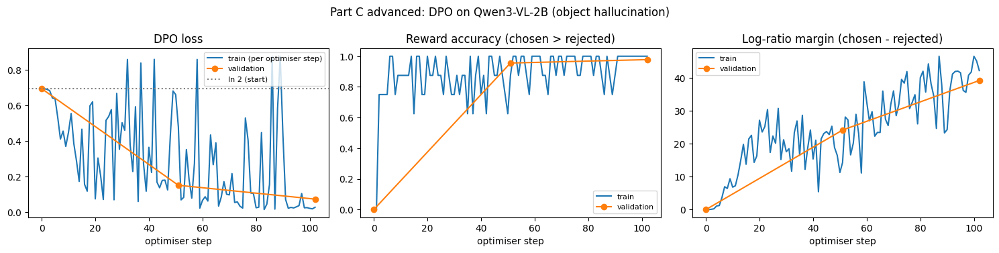

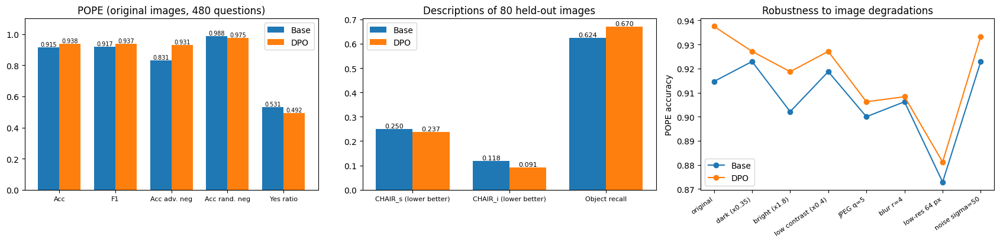

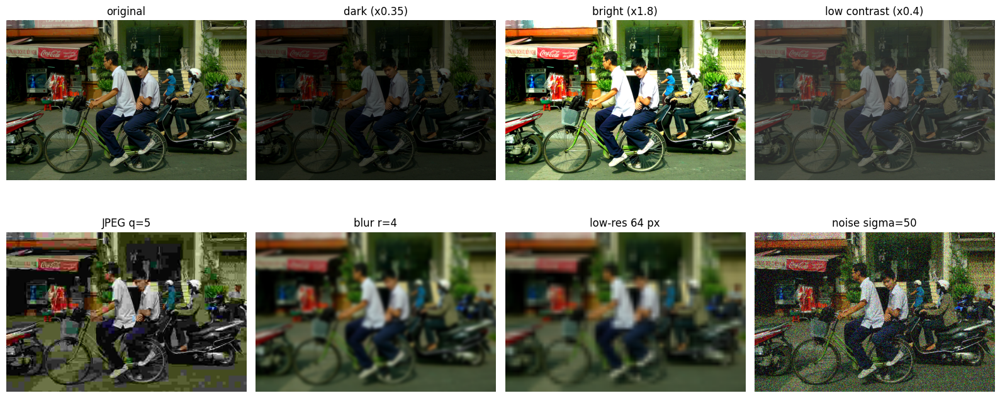

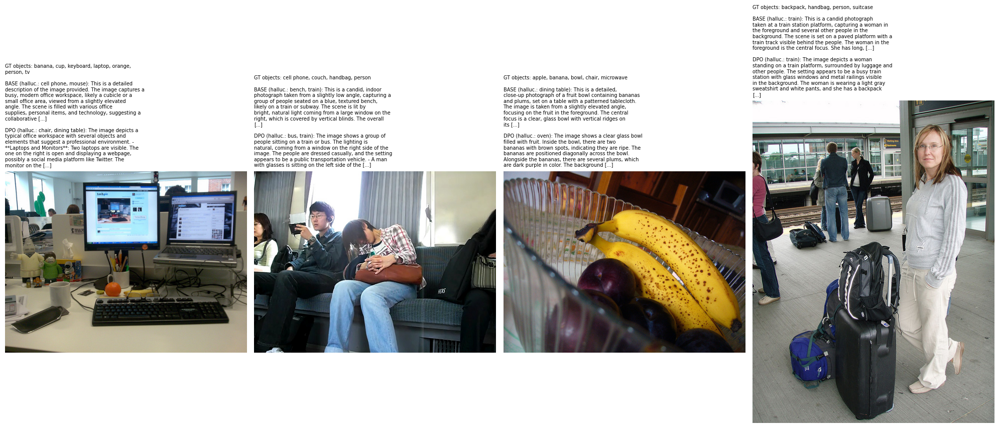

In [4]:
from Code.partC_dpo_vlm import run_partC_vlm
CV = run_partC_vlm()
plt.close('all')
print('偏好資料組成：', CV['pair_stats'])
display(CV['pope'])
display(CV['chair'])
display(CV['examples'].head(5))
for f in CV['figures'].values():
    display(f)

---
### 下載結果
把 `Output/`（CSV、圖表、所有生成紀錄、Gemini 回覆快取）與 `Checkpoints/*/history.json` 壓縮成 `HW07_results.zip`（不含 LoRA 權重）。

In [3]:
import zipfile
with zipfile.ZipFile('HW07_results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for root in ('Output', 'Checkpoints'):
        for d, _, files in os.walk(root):
            for f in files:
                if not f.endswith(('.safetensors', '.bin')):
                    z.write(os.path.join(d, f))
print(f"HW07_results.zip: {os.path.getsize('HW07_results.zip') / 2**20:.1f} MiB")
if IN_COLAB:
    from google.colab import files
    files.download('HW07_results.zip')

HW07_results.zip: 11.5 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>